# 7.3 Связи между переменными и вопросы к данным — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 07 «Разведочный анализ» · страница 7.3.

В ноутбуке шесть блоков кода со страницы. Три блока раздела «Код» идут подряд, как на странице: матрица пар и корреляций, сравнение сегментов, разметка ряда по дням. Затем три нюанса: перебор пар в шуме, агрегация по месяцам и неполный последний день. Данные учебные: выгрузка клиентов и дневные метрики из общего набора темы `data/eda/`.

Шаблон ноутбука из четвёртого блока страницы лежит рядом готовым файлом `eda_template.ipynb`.

**Как работать.** Выполняйте ячейки по порядку сверху вниз: первый блок чистит выгрузку и сохраняет её для второго.

Вывод получен на Python 3.13, NumPy 2.5, pandas 3.0, SciPy 1.18, seaborn 0.13 и matplotlib 3.10.

## Где лежат данные

Код страницы читает файлы по пути от корня папки с материалами: `data/eda/clients_export.csv` и `data/eda/daily_metrics.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей. Туда же первый блок сохранит очищенную таблицу `clients_clean.parquet` и рисунки `pairplot.svg` и `corr.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import numpy as np
import pandas as pd
import scipy
import seaborn

root = pathlib.Path.cwd()
while not (root / "data" / "eda").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/eda/
assert (root / "data" / "eda" / "daily_metrics.csv").exists(), \
    "Не найдена папка data/eda/. Скачайте общий набор темы 07 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| seaborn", seaborn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | seaborn 0.13.2 | matplotlib 3.10.0


## Код: пары, сегменты, ряд

### Сильнее всего связаны визиты и заказы, возраст — ни с чем

11701 клиентов после чистки


{'visits_q1': 11701, 'orders_q1': 11701, 'age': 11350, 'check': 10035, 'tier': 11701}
           visits_q1  orders_q1   age  check  tier
visits_q1       1.00       0.56 -0.01  -0.03  0.38
orders_q1       0.56       1.00 -0.01  -0.09  0.21
age            -0.01      -0.01  1.00   0.01 -0.01
check          -0.03      -0.09  0.01   1.00 -0.03
tier            0.38       0.21 -0.01  -0.03  1.00
           visits_q1  orders_q1   age  check  tier
visits_q1       1.00       0.53 -0.02   0.03  0.37
orders_q1       0.53       1.00 -0.01  -0.01  0.21
age            -0.02      -0.01  1.00   0.01 -0.01
check           0.03      -0.01  0.01   1.00 -0.02
tier            0.37       0.21 -0.01  -0.02  1.00


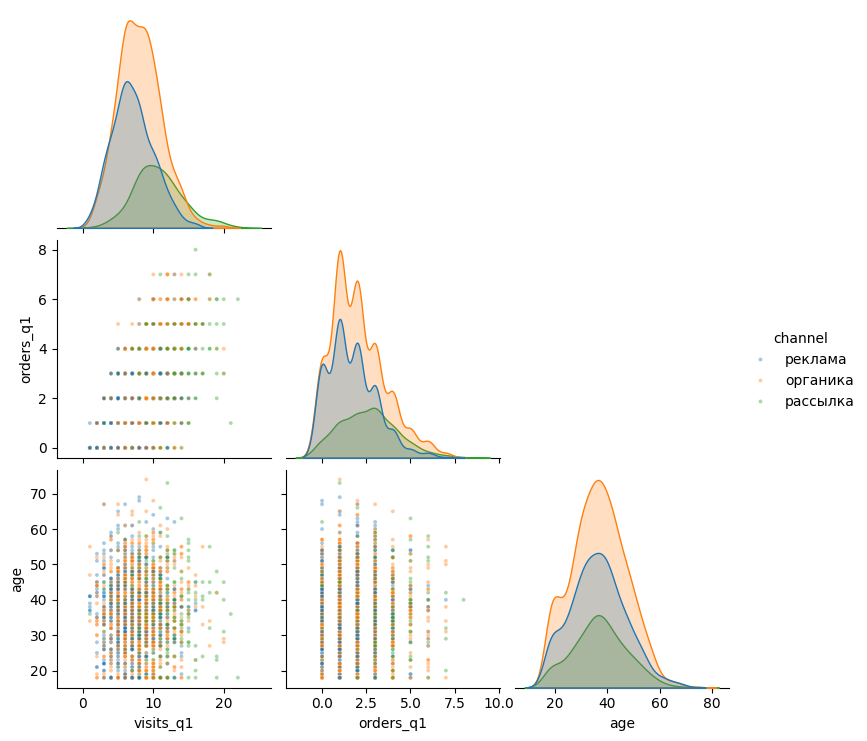

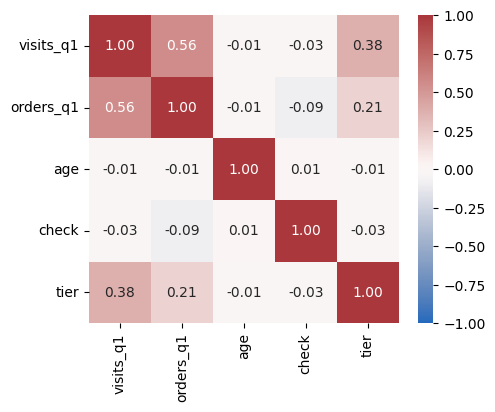

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

raw = pd.read_csv("data/eda/clients_export.csv")
df = (raw.dropna(subset=["client_id"])                 # чистка из 7.1
         .drop_duplicates("client_id")                 # копии отличаются визитами на 1: пока берём первую
         .query("orders_q1 >= 0 and channel != '-' and spend_q1 < 1e6")
         .assign(age=lambda d: d["age"].where(d["age"] != 99),
                 check=lambda d: (d["spend_q1"] / d["orders_q1"]).where(d["orders_q1"] > 0)))
df.to_parquet("clients_clean.parquet")                  # следующие блоки читают отсюда
print(len(df), "клиентов после чистки")

# нижний треугольник матрицы парных графиков, цвет — канал
g = sns.pairplot(df.sample(2_000, random_state=703), vars=["visits_q1", "orders_q1", "age"],
                 hue="channel", corner=True, plot_kws={"s": 8, "alpha": 0.4})
g.savefig("pairplot.svg")

cols = ["visits_q1", "orders_q1", "age", "check", "tier"]
print(df[cols].count().to_dict())                       # у каждой пары свои строки
pear = df[cols].corr().round(2)                         # tier здесь просто число 1–5
spear = df[cols].corr(method="spearman").round(2)
print(pear, spear, sep="\n")

plt.figure(figsize=(5, 4))
sns.heatmap(pear, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag").figure.savefig("corr.svg")

Файлы pairplot.svg и corr.svg код сохраняет рядом; в страницу они не вшиты. Карта под блоком нарисована по этим же числам.

### У рассылки самый высокий чек, и порядок каналов держится на каждом уровне

In [3]:
import pandas as pd

df = pd.read_parquet("clients_clean.parquet")            # сохранил первый блок
seg = df.groupby("channel")["check"]
print(seg.describe().round(0).sort_values("50%"))
print((seg.median() / df["check"].median() - 1).mul(100).round(1))   # медиана сегмента к общей, %

# порядок каналов внутри каждого уровня лояльности
tab = df.pivot_table(index="tier", columns="channel", values="check", aggfunc="median")
print(tab[["реклама", "органика", "рассылка"]].round(0))

           count    mean     std    min     25%     50%     75%      max
channel                                                                 
реклама   3189.0  3823.0  6201.0  445.0  1950.0  2607.0  3687.0  97400.0
органика  5037.0  4233.0  6032.0  537.0  2225.0  3058.0  4300.0  97650.0
рассылка  1809.0  4563.0  5148.0  785.0  2535.0  3475.0  4930.0  64300.0
channel
органика     2.5
рассылка    16.5
реклама    -12.6
Name: check, dtype: float64
channel  реклама  органика  рассылка
tier                                
1         2620.0    3088.0    3550.0
2         2630.0    3049.0    3406.0
3         2550.0    3132.0    3565.0
4         2625.0    2960.0    3538.0
5         2577.0    2953.0    3118.0


### В выгрузке нет четырёх дней, последний неполный, выходные на четверть выше будней

In [4]:
import pandas as pd

d = pd.read_csv("data/eda/daily_metrics.csv", parse_dates=["date"]).set_index("date")
cal = pd.date_range("2026-01-01", "2026-03-31", freq="D")    # какие дни должны быть
print("строк:", len(d), "| дней в квартале:", len(cal))
print("нет в выгрузке:", cal.difference(d.index).strftime("%d.%m").tolist())

d = d.reindex(cal)                    # дыра — явные NaN, а не склейка 9 и 14 февраля
d["flag"] = "ok"
d.loc[d["revenue"].isna(), "flag"] = "разрыв"
d.loc[d.index[-1], "flag"] = "неполный день"            # выгрузка снята днём 31.03
print(d["flag"].value_counts().to_dict())

ok = d[d["flag"] == "ok"]
week = ok["revenue"].groupby(ok.index.dayofweek).mean() / ok["revenue"].mean()
print(week.round(2).set_axis("пн вт ср чт пт сб вс".split()).to_dict())

строк: 86 | дней в квартале: 90
нет в выгрузке: ['10.02', '11.02', '12.02', '13.02']
{'ok': 85, 'разрыв': 4, 'неполный день': 1}
{'пн': 0.95, 'вт': 0.94, 'ср': 0.95, 'чт': 0.89, 'пт': 0.92, 'сб': 1.17, 'вс': 1.15}


Рисунок под блоком — тот же ряд выручки по дням с разметкой разрыва и неполного дня.

## Три нюанса

### Шум даёт 9 «значимых» пар из 190, и ни одна не повторяется на новых днях

In [5]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(733)
n, k = 86, 20                         # 86 дней, 20 метрик из чистого шума
X = rng.normal(size=(n, k))
pairs = [(i, j) for i in range(k) for j in range(i + 1, k)]
res = [stats.pearsonr(X[:, i], X[:, j]) for i, j in pairs]
hits = [pr for pr, rr in zip(pairs, res) if rr.pvalue < 0.05]
print(len(pairs), "пар,", len(hits), "«значимых» при p < 0,05")
print("сильнейшая |r| =", round(max(abs(rr.statistic) for rr in res), 2))

Y = rng.normal(size=(n, k))           # те же 20 метрик, следующие 86 дней
again = sum(stats.pearsonr(Y[:, i], Y[:, j]).pvalue < 0.05 for i, j in hits)
print("подтвердились на новых днях:", again, "из", len(hits))

def finds(X):                         # число «находок» в одной матрице
    r = np.corrcoef(X, rowvar=False)[np.triu_indices(k, 1)]
    t = r * np.sqrt((n - 2) / (1 - r ** 2))
    return (2 * stats.t.sf(abs(t), n - 2) < 0.05).sum()
print("в среднем за 1 000 повторов:", np.mean([finds(rng.normal(size=(n, k))) for _ in range(1000)]))

190 пар, 9 «значимых» при p < 0,05
сильнейшая |r| = 0.31
подтвердились на новых днях: 0 из 9


в среднем за 1 000 повторов: 9.511


### По сумме февраль просел на 17%, в пересчёте на день вырос на 7%

In [6]:
import pandas as pd

d = pd.read_csv("data/eda/daily_metrics.csv", parse_dates=["date"])
m = d.groupby(d["date"].dt.month)["revenue"].agg(total="sum", days="size", per_day="mean")
m["total_vs_jan_%"] = (m["total"] / m["total"].iloc[0] - 1) * 100
m["per_day_vs_jan_%"] = (m["per_day"] / m["per_day"].iloc[0] - 1) * 100
print(m.assign(total=m["total"] / 1e6, per_day=m["per_day"] / 1e3).round(1))   # млн ₽ и тыс. ₽

w = d.set_index("date")["revenue"].resample("W").agg(["sum", "size"])
print(w.loc["2026-02-02":"2026-02-22"])         # неделя с разрывом

      total  days  per_day  total_vs_jan_%  per_day_vs_jan_%
date                                                        
1      13.3    31    428.9             0.0               0.0
2      11.0    24    457.6           -17.4               6.7
3      14.8    31    476.6            11.1              11.1
                  sum  size
date                       
2026-02-08  2967700.0     7
2026-02-15  1480800.0     3
2026-02-22  3110200.0     7


### Неполный последний день — это «−56%» и вдвое большая корреляция изменений

In [7]:
import pandas as pd

d = pd.read_csv("data/eda/daily_metrics.csv", parse_dates=["date"]).set_index("date")
print(d.tail(3))
print(f"31.03 к 30.03: {d['revenue'].pct_change().iloc[-1]:+.0%}")
tue = d.loc[d.index.dayofweek == 1, "revenue"]
print(f"31.03 к медиане четырёх прошлых вторников: {tue.iloc[-1] / tue.iloc[-5:-1].median():.0%}")

cols = ["app_installs", "support_tickets"]
r = lambda x: x.diff().corr().iloc[0, 1].round(2)
cal = d[cols].asfreq("D")                       # разрыв — NaN, через него разность не считается
print("r изменений за день, строки подряд:", r(d[cols]))
print("по календарю:                      ", r(cal))
print("по календарю, без 31 марта:        ", r(cal.iloc[:-1]))

            app_installs  support_tickets   revenue
date                                               
2026-03-29           527               71  541000.0
2026-03-30           458               61  433300.0
2026-03-31           212               28  190800.0
31.03 к 30.03: -56%
31.03 к медиане четырёх прошлых вторников: 42%
r изменений за день, строки подряд: 0.37
по календарю:                       0.37
по календарю, без 31 марта:         0.17
